<a href="https://colab.research.google.com/github/Hema392/ITA0314-Mobile-Computing-/blob/main/Exp20.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


EXPERIMENT 20: CDMA

User 1 Data: [1, 0, 1, 1]
User 1 Spread: [ 1 -1  1 -1 -1  1 -1  1  1 -1  1 -1  1 -1  1 -1]

User 2 Data: [0, 0, 1, 0]
User 2 Spread: [-1 -1  1  1 -1 -1  1  1  1  1 -1 -1 -1 -1  1  1]

User 3 Data: [1, 1, 0, 1]
User 3 Spread: [ 1 -1 -1  1  1 -1 -1  1 -1  1  1 -1  1 -1 -1  1]

Composite Signal:
[ 1 -3  1  1 -1 -1 -1  3  1  1  1 -3  1 -3  1  1]

Despreading Results:
User 1 Correlator: [ 1. -1.  1.  1.]
Recovered Data: [1, 0, 1, 1]
Status: OK
User 2 Correlator: [-1. -1.  1. -1.]
Recovered Data: [0, 0, 1, 0]
Status: OK
User 3 Correlator: [ 1.  1. -1.  1.]
Recovered Data: [1, 1, 0, 1]
Status: OK


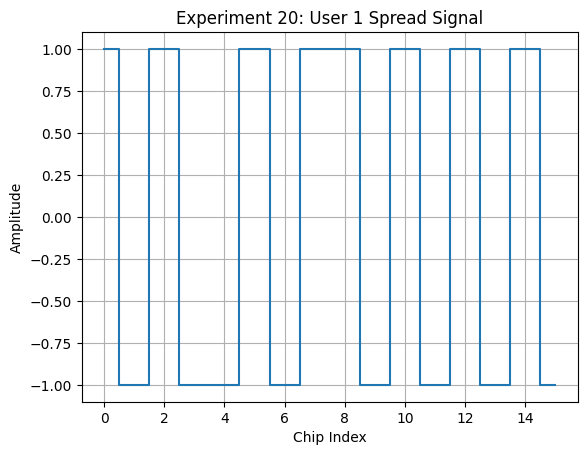

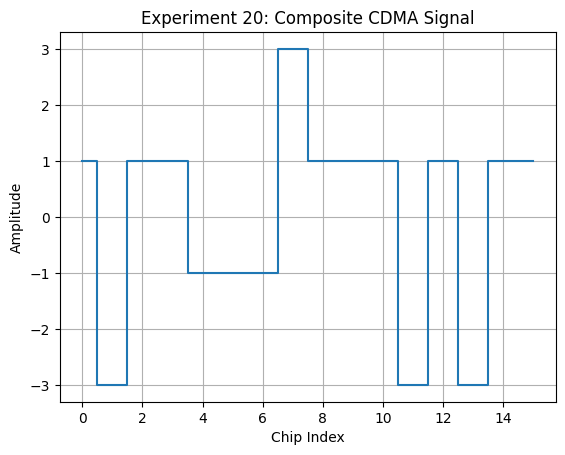

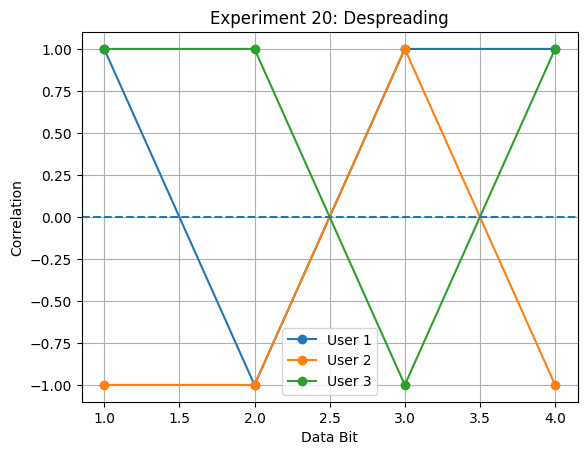

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math
print("\nEXPERIMENT 20: CDMA")

W = np.array([
    [1, 1, 1, 1],
    [1,-1, 1,-1],
    [1, 1,-1,-1],
    [1,-1,-1, 1]
])

bits = {
    1: [1,0,1,1],
    2: [0,0,1,0],
    3: [1,1,0,1]
}

L = 4
nbits = 4

def bpsk(b):
    return 2*np.array(b)-1

tx = np.zeros(nbits*L)
spread_signals = {}

for u,b in bits.items():
    spread = np.repeat(bpsk(b),L) * np.tile(W[u],nbits)

    spread_signals[u] = spread
    print("\nUser",u,"Data:",b)
    print("User",u,"Spread:",spread.astype(int))

    tx += spread

print("\nComposite Signal:")
print(tx.astype(int))

correlators = {}

print("\nDespreading Results:")

for u,b in bits.items():
    corr = (tx*np.tile(W[u],nbits)).reshape(nbits,L).sum(axis=1)/L

    rec = (corr>0).astype(int)
    correlators[u] = corr

    print("User",u,"Correlator:",corr)
    print("Recovered Data:",rec.tolist())
    print("Status:", "OK" if rec.tolist()==b else "ERROR")

plt.figure()
plt.step(range(len(spread_signals[1])),
         spread_signals[1], where='mid')
plt.xlabel("Chip Index")
plt.ylabel("Amplitude")
plt.title("Experiment 20: User 1 Spread Signal")
plt.grid()
plt.show()

plt.figure()
plt.step(range(len(tx)), tx, where='mid')
plt.xlabel("Chip Index")
plt.ylabel("Amplitude")
plt.title("Experiment 20: Composite CDMA Signal")
plt.grid()
plt.show()

plt.figure()
for u in correlators:
    plt.plot(range(1,nbits+1), correlators[u],
             marker='o', label=f"User {u}")

plt.axhline(0, linestyle='--')
plt.xlabel("Data Bit")
plt.ylabel("Correlation")
plt.title("Experiment 20: Despreading")
plt.legend()
plt.grid()
plt.show()